In [1]:

import tensorflow as tf
from tensorflow.keras import layers, models


In [3]:
train_data = tf.keras.utils.image_dataset_from_directory(
    r"C:\Users\VIVEK V\OneDrive\Desktop\DL\Deep learning\cats_vs_dogs_dataset\dataset\train",
    image_size=(64, 64),
    batch_size=32
)

test_data = tf.keras.utils.image_dataset_from_directory(
    r"C:\Users\VIVEK V\OneDrive\Desktop\DL\Deep learning\cats_vs_dogs_dataset\dataset\test",
    image_size=(64, 64),
    batch_size=32,
    shuffle=False
)

Found 80 files belonging to 2 classes.


Found 20 files belonging to 2 classes.


In [ ]:
model=models.Sequential([
    layers.Input(shape=(64,64,3)),
    layers.Rescaling(1./255),
    layers.Conv2D(32,(3,3),activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(64,activation='relu'),
    layers.Dense(len(train_data.class_names),activation='softmax')
])

In [ ]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
model.fit(train_data,epochs=5)

Epoch 1/5


c:\Users\VIVEK V\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.5250 - loss: 1.8421
Epoch 2/5
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.5000 - loss: 1.4951
Epoch 3/5
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.5000 - loss: 0.9291
Epoch 4/5
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.6250 - loss: 0.6762
Epoch 5/5
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.6000 - loss: 0.6848


In [ ]:
loss,acc=model.evaluate(test_data)
acc

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.5000 - loss: 0.6264


0.5

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 399ms/step


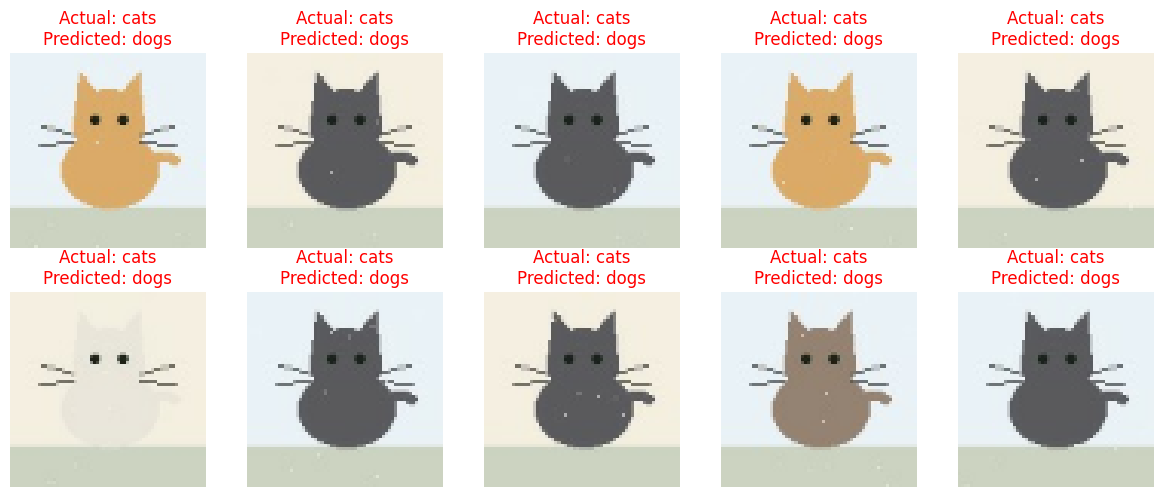

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

class_names = train_data.class_names

for images, labels in test_data.take(1):

    predictions = model.predict(images)
    predicted_labels = np.argmax(predictions, axis=1)

    plt.figure(figsize=(12, 5))

    for i in range(10):
        plt.subplot(2, 5, i+1)

        plt.imshow(images[i].numpy().astype('uint8'))

        actual = class_names[labels[i].numpy()]
        predicted = class_names[predicted_labels[i]]

        if actual == predicted:
            colour = 'green'
        else:
            colour = 'red'

        plt.title(f"Actual: {actual}\nPredicted: {predicted}", color=colour)
        plt.axis('off')

    plt.tight_layout()
    plt.show()